In [7]:
from os import wait

import numpy as np
from IPython.core.display_functions import clear_output
from numpy import random
import matplotlib.pyplot as plt
from IPython.display import clear_output

Creating training data and plotting it:

Training data: [[ 2  3]
 [ 4  6]
 [ 6  6]
 [ 7  9]
 [ 8 12]]


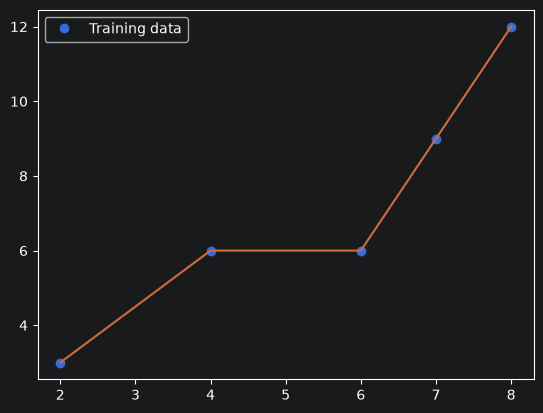

In [8]:
training = np.array([1,2,3,4,5,6,7,8,9,10]).reshape(-1,2).copy()
deviaion = random.randint(4,size=(training.shape))-2
training = training-deviaion
x_input = training[:,0]
y_output = training[:,1]
print(f"Training data: {training}")
plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, y_output)
plt.legend()
plt.show()

Cost function and testing it:

In [9]:
#Cost function:
def cost_function(y,y_hat):
    return np.average((y-y_hat)**2)/2

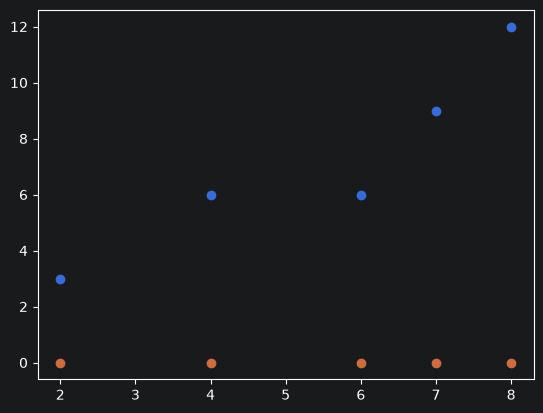

Cost function: 0.0


In [10]:
#Weight:
w = 0
#Bias:
b = 0
y_hat = x_input * w + b
plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, y_hat,'o',label="Trained data")
plt.show()
print(f"Cost function: {cost_function(y_output, y_output)}")

Brute force linear regression:

Cost value: 140.66 Values: -1.59,0.25
Cost value: 24.31 Values: 2.49,0.17
Cost value: 9.38 Values: 0.76,-0.91
Cost value: 3.37 Values: 1.39,2.00
Cost value: 1.33 Values: 1.62,-2.53
Cost value: 0.69 Values: 1.20,0.57


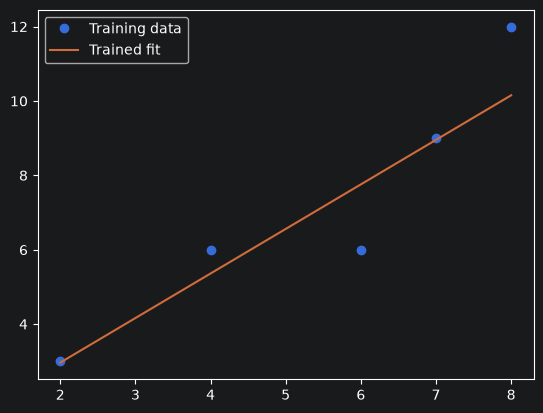

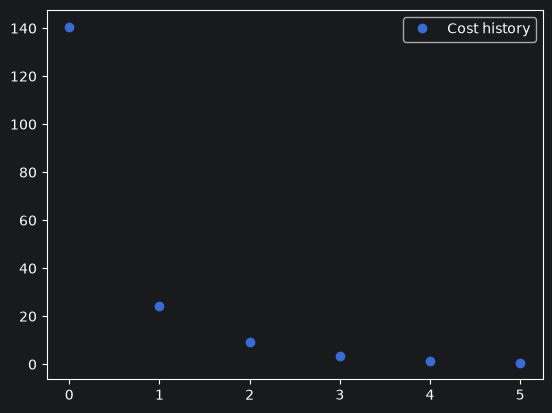

In [11]:
#Brute force linear regression:
cost = np.inf
w,b = 0,0
cost_history = []
for i in range(100):
    new_w,new_b = np.random.uniform(-5,5,size=(2))
    y_hat = x_input * new_w + new_b
    new_cost = cost_function(y_hat, y_output)
    if new_cost < cost:
        cost_history.append(new_cost)
        cost = new_cost
        w,b = new_w,new_b
        print(f"Cost value: {new_cost:.2f} Values: {w:.2f},{b:.2f}")

plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, x_input*w + b ,label="Trained fit")
plt.legend()
plt.show()

plt.plot(cost_history,'o', label="Cost history")
plt.legend()
plt.show()

In [12]:
#making it a function:
def brute_force_linear_regression(x_input, iterations=100):
    cost = np.inf
    w, b = 0, 0
    for i in range(iterations):
        new_w, new_b = np.random.uniform(-5, 5, size=(2))
        y_hat = x_input * new_w + new_b
        new_cost = cost_function(y_hat, y_output)
        if new_cost < cost:
            cost = new_cost
            w, b = new_w, new_b
    return w,b

Testing gradient descent

In [39]:
def calc_cost(w,b,x,y):
    return cost_function(x*w+b,y)

Cost value: 50.22 Values: -0.34,-0.28
Cost value: 46.85 Values: -0.28,-0.27
Cost value: 43.70 Values: -0.22,-0.26
Cost value: 40.77 Values: -0.17,-0.25
Cost value: 38.03 Values: -0.12,-0.24
Cost value: 35.49 Values: -0.07,-0.23
Cost value: 33.11 Values: -0.02,-0.22
Cost value: 30.90 Values: 0.03,-0.22
Cost value: 28.84 Values: 0.07,-0.21
Cost value: 26.92 Values: 0.12,-0.20
Cost value: 25.13 Values: 0.16,-0.20
Cost value: 23.46 Values: 0.20,-0.19
Cost value: 21.91 Values: 0.24,-0.18
Cost value: 20.46 Values: 0.28,-0.18
Cost value: 19.11 Values: 0.31,-0.17
Cost value: 17.86 Values: 0.35,-0.17
Cost value: 16.68 Values: 0.38,-0.16
Cost value: 15.59 Values: 0.42,-0.15
Cost value: 14.57 Values: 0.45,-0.15
Cost value: 13.62 Values: 0.48,-0.14
Cost value: 12.74 Values: 0.51,-0.14
Cost value: 11.92 Values: 0.54,-0.14
Cost value: 11.15 Values: 0.56,-0.13
Cost value: 10.43 Values: 0.59,-0.13
Cost value: 9.77 Values: 0.62,-0.12
Cost value: 9.15 Values: 0.64,-0.12
Cost value: 8.57 Values: 0.67,-0.

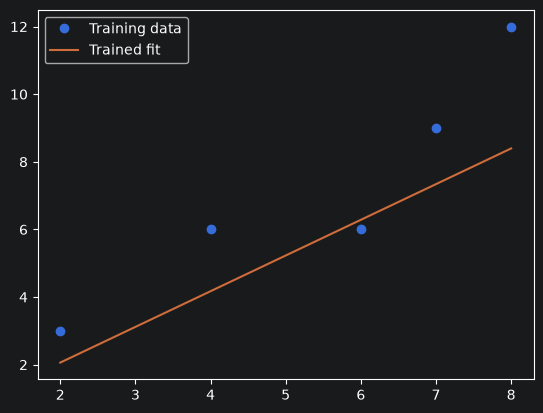

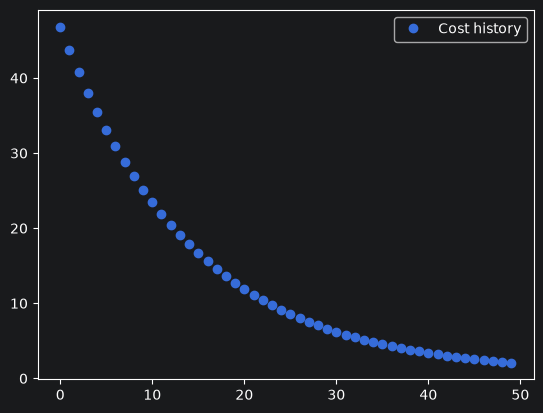

In [42]:
#w = 2-a*delta(J(w,b))/delta(w)
#b = 2-a*delta(J(w,b))/delta(b)

w,b = np.random.uniform(-1,1,size=(2))
cost = calc_cost(w,b,x_input,y_output)
print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")

cost_history = []
learning_rate = 0.001
delta = 0.001

cut_off = 0.1

while(True):
    new_w = w - learning_rate * (calc_cost(w+delta,b,x_input,y_output)-cost)/delta
    new_b = b - learning_rate * (calc_cost(w,b+delta,x_input,y_output)-cost)/delta
    w,b = new_w,new_b

    y_hat = x_input*w + b
    new_cost = cost_function(y_hat, y_output)
    if (abs(new_cost-cost) < cut_off):
        break
    cost = new_cost
    cost_history.append(cost)
    print(f"Cost value: {cost:.2f} Values: {w:.2f},{b:.2f}")


plt.plot(x_input, y_output, 'o', label="Training data")
plt.plot(x_input, x_input*w + b ,label="Trained fit")
plt.legend()
plt.show()

plt.plot(cost_history,'o', label="Cost history")
plt.legend()
plt.show()